# 3. Algoritmo da Transformada Rápida de Fourier (FFT — Radix-2 DIT)

A computação da DFT via matriz arcaica exige $\mathcal{O}(N^2)$ operações complexas (uma matriz $N \times N$ preenchida e percorrida por laços aninhados). O algoritmo da FFT de Cooley-Tukey reduz essa complexidade para $\mathcal{O}(N \log_2 N)$ dividindo o sinal de tamanho $N$ em partes pares e ímpares:

$$X[k] = E[k] + W_N^k \cdot O[k], \quad k = 0, 1, \dots, \frac{N}{2}-1$$
$$X\left[k + \frac{N}{2}\right] = E[k] - W_N^k \cdot O[k], \quad k = 0, 1, \dots, \frac{N}{2}-1$$

onde $E[k]$ é a DFT das amostras pares e $O[k]$ é a DFT das amostras ímpares.

/home/guilhermemendes/Área de trabalho/Capacitacao_PDS/Relatorio_2/Algoritmo_DFT_e_IDFT.ipynb:115: SyntaxWarning: invalid escape sequence '\p'
  "            real = math.cos(angulo)\n",


=== ESPECTRO DFT INICIAL X[k] (Retangular | Polar) ===
[ 0]    4.000 +   0.000j  |  Mag:   4.000  Fase:     0.0°
[ 1]    0.000 -   2.000j  |  Mag:   2.000  Fase:   -90.0°
[ 2]    0.000 +   0.000j  |  Mag:   0.000  Fase:     0.0°
[ 3]   -0.000 +   2.000j  |  Mag:   2.000  Fase:    90.0°


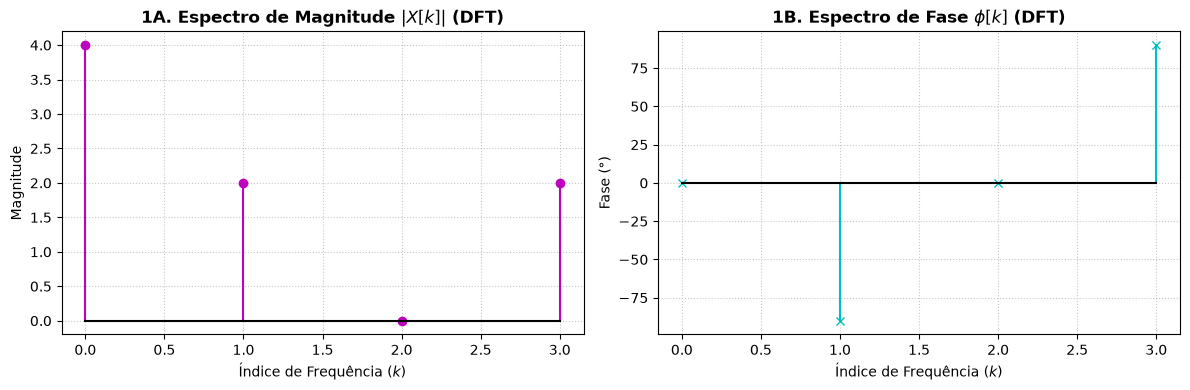

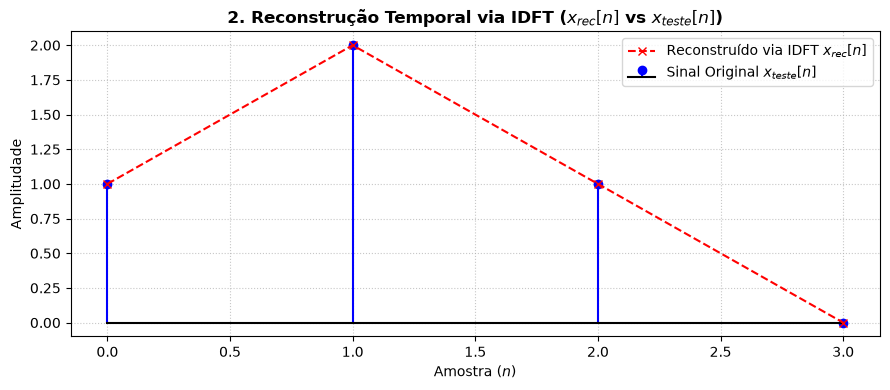

=== VALIDAÇÃO EXPERIMENTAL DAS PROPRIEDADES DA DFT ===
1. Linearidade - Erro Máximo: 3.55e-15
2. Deslocamento Temporal - Erro Máximo: 6.31e-14
3. Deslocamento na Frequência - Erro Máximo: 5.81e-14
4. Reversão Temporal - Erro Máximo: 5.41e-14
5. Conjugação Complexa - Erro Máximo: 5.15e-14
6. Simetria Conjugada (Sinal Real) - Erro Máximo: 5.49e-14
7. Convolução Circular no Tempo - Erro Máximo: 1.38e-13
8. Multiplicação Ponto a Ponto - Erro Máximo: 3.13e-14
9. Teorema de Parseval - Erro Absoluto: 8.88e-15
10. Periodicidade na Frequência - Erro Máximo: 5.32e-14
=== Comparação entre DFT Arcaica e FFT Manual ===
DFT Arcaica:
[36.+0.00000000e+00j -4.+9.65685425e+00j -4.+4.00000000e+00j
 -4.+1.65685425e+00j -4.-3.91886976e-15j -4.-1.65685425e+00j
 -4.-4.00000000e+00j -4.-9.65685425e+00j]

FFT Manual:
[36.+0.j         -4.+9.65685425j -4.+4.j         -4.+1.65685425j
 -4.+0.j         -4.-1.65685425j -4.-4.j         -4.-9.65685425j]
Erro Médio Absoluto (MAE) entre DFT Arcaica e FFT Manual: 9.79e-1

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import time
from ipynb.fs.full.Algoritmo_DFT_e_IDFT import dft_imp

def fft_radix2(x):
    """
    Implementação recursiva da FFT Radix-2 (Cooley-Tukey DIT).
    O comprimento de x deve ser uma potência de 2.
    """
    x = np.asarray(x, dtype=complex)
    N = len(x)
    
    if N <= 1:
        return x
    
    if N % 2 != 0:
        raise ValueError("O tamanho do sinal deve ser uma potência de 2.")
        
    # Separação das amostras pares e ímpares
    pares = fft_radix2(x[0::2])
    impares = fft_radix2(x[1::2])
    
    # Fatores de rotação (Twiddle factors)
    k = np.arange(N // 2)
    twiddle = np.exp(-2j * np.pi * k / N)
    
    # Estrutura Butterfly (Borboleta)
    X_metade1 = pares + twiddle * impares
    X_metade2 = pares - twiddle * impares
    
    return np.concatenate([X_metade1, X_metade2])

# Validação da FFT comparando com a DFT implementada
x_fft_teste = np.array([1,2,3,4,5,6,7,8], dtype=float)
res_dft = dft_imp(x_fft_teste)
res_fft = fft_radix2(x_fft_teste)

print("=== Comparação entre DFT Arcaica e FFT Manual ===")
print("DFT Arcaica:")
print(res_dft)
print("\nFFT Manual:")
print(res_fft)

mae_fft = np.mean(np.abs(res_dft - res_fft))
print(f"Erro Médio Absoluto (MAE) entre DFT Arcaica e FFT Manual: {mae_fft:.2e}")

# 4. Comparação de Desempenho e Exatidão Numérica

Nesta etapa, medimos o impacto computacional de construir explicitamente a matriz $W$ e realizar a multiplicação matricial por laços ($\mathcal{O}(N^2)$) em comparação com o algoritmo FFT ($\mathcal{O}(N \log_2 N)$) e a biblioteca otimizada NumPy (`np.fft.fft`).

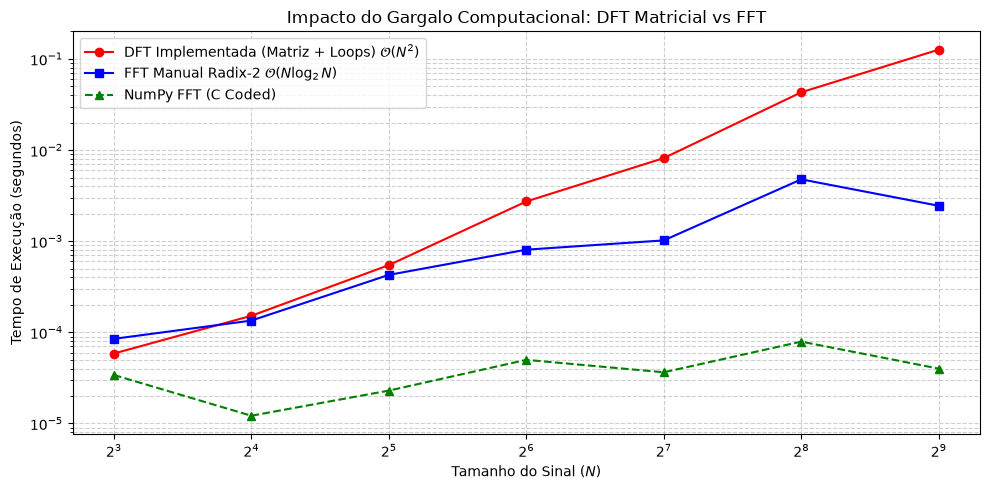

Tamanho N | MAE (DFT Arcaica vs FFT Manual)
------------------------------------------
        8 | 1.37e-15
       16 | 1.06e-14
       32 | 2.11e-14
       64 | 4.88e-14
      128 | 1.70e-13
      256 | 5.30e-13
      512 | 1.44e-12


In [30]:
potencias = np.arange(3, 10)  # N de 2^3 (8) ate 2^9 (512)
tamanhos_N = 2**potencias

tempos_dft = []
tempos_fft_manual = []
tempos_numpy = []
maes = []

for N_val in tamanhos_N:
    x_sinal = np.random.randn(N_val)
    
    # Tempo DFT Arcaica
    t0 = time.perf_counter()
    res_dft = dft_imp(x_sinal)
    t1 = time.perf_counter()
    tempos_dft.append(t1 - t0)
    
    # Tempo FFT Manual
    t0 = time.perf_counter()
    res_fft = fft_radix2(x_sinal)
    t1 = time.perf_counter()
    tempos_fft_manual.append(t1 - t0)
    
    # Tempo NumPy FFT
    t0 = time.perf_counter()
    res_np = np.fft.fft(x_sinal)
    t1 = time.perf_counter()
    tempos_numpy.append(t1 - t0)
    
    # Calculo do MAE em relacao à DFT arcaica
    mae = np.mean(np.abs(res_dft - res_fft))
    maes.append(mae)

# Gráfico comparativo de tempo de execução
plt.figure(figsize=(10, 5))
plt.plot(tamanhos_N, tempos_dft, 'o-', label=r'DFT Implementada (Matriz + Loops) $\mathcal{O}(N^2)$', color='red')
plt.plot(tamanhos_N, tempos_fft_manual, 's-', label=r'FFT Manual Radix-2 $\mathcal{O}(N \log_2 N)$', color='blue')
plt.plot(tamanhos_N, tempos_numpy, '^--', label='NumPy FFT (C Coded)', color='green')

plt.xscale('log', base=2)
plt.yscale('log')
plt.xlabel('Tamanho do Sinal ($N$)')
plt.ylabel('Tempo de Execução (segundos)')
plt.title('Impacto do Gargalo Computacional: DFT Matricial vs FFT')
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Tabela de Erro Médio Absoluto (MAE)
print("Tamanho N | MAE (DFT Arcaica vs FFT Manual)")
print("-" * 42)
for N_val, mae in zip(tamanhos_N, maes):
    print(f"{N_val:9d} | {mae:.2e}")